# 02 — Exploration (Spark SQL) et séparation entraînement / test

Entrée : `data/propre/transactions.parquet`.
Sortie : `data/ml/train.parquet` (80 %) et `data/ml/test.parquet` (20 %).

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("fraude-02-exploration")
         .master("spark://spark-master:7077")
         .config("spark.driver.host", "spark-master")
         .config("spark.driver.memory", "2g")
         .config("spark.executor.memory", "2g")
         .config("spark.sql.shuffle.partitions", "18")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", "file:///tmp/spark-events")
         .getOrCreate())

DATA = "/opt/spark-data"
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/22 00:05:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
df = spark.read.parquet(DATA + "/propre/transactions.parquet")
df.createOrReplaceTempView("transactions")
print("Lignes :", df.count())

[Stage 1:===================>                                       (3 + 6) / 9]

Lignes : 6292904


## Déséquilibre des classes

In [3]:
spark.sql("""
    SELECT label, COUNT(*) AS nb
    FROM transactions
    GROUP BY label
""").show()

[Stage 4:=======================================>                   (6 + 3) / 9]

+-----+-------+
|label|     nb|
+-----+-------+
|  0.0|6284787|
|  1.0|   8117|
+-----+-------+



8 117 fraudes sur 6 292 904 transactions, soit 0,13 %. Les classes sont très déséquilibrées : un modèle qui répond toujours « normal » aurait 99,87 % d'accuracy. On utilisera donc la PR-AUC, la précision et le rappel sur la classe fraude.

## Fraudes par type de transaction

In [4]:
spark.sql("""
    SELECT type,
           COUNT(*)                   AS nb,
           SUM(label)                 AS nb_fraudes,
           ROUND(100 * AVG(label), 3) AS taux_fraude_pct
    FROM transactions
    GROUP BY type
    ORDER BY nb_fraudes DESC
""").show()

[Stage 7:===================>                                       (3 + 6) / 9]

+--------+-------+----------+---------------+
|    type|     nb|nb_fraudes|taux_fraude_pct|
+--------+-------+----------+---------------+
|CASH_OUT|2213096|    4068.0|          0.184|
|TRANSFER| 527206|    4049.0|          0.768|
|   DEBIT|  40976|       0.0|            0.0|
| CASH_IN|1383815|       0.0|            0.0|
| PAYMENT|2127811|       0.0|            0.0|
+--------+-------+----------+---------------+



Les fraudes n'existent que dans `TRANSFER` (0,77 %) et `CASH_OUT` (0,18 %). On garde donc seulement ces deux types pour le modèle.

## Montants (TRANSFER et CASH_OUT)

In [5]:
spark.sql("""
    SELECT label,
           ROUND(MIN(amount), 2)                    AS min,
           ROUND(percentile_approx(amount, 0.5), 2) AS mediane,
           ROUND(AVG(amount), 2)                    AS moyenne,
           ROUND(MAX(amount), 2)                    AS max
    FROM transactions
    WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY label
""").show()

[Stage 10:================================>                         (5 + 4) / 9]

+-----+----+---------+----------+-------------+
|label| min|  mediane|   moyenne|          max|
+-----+----+---------+----------+-------------+
|  0.0|0.01|171012.08| 313971.95|9.244551664E7|
|  1.0| 0.0|440962.56|1468601.16|        1.0E7|
+-----+----+---------+----------+-------------+



Les fraudes portent sur des montants plus élevés (médiane 440 963 contre 171 012). Le maximum des fraudes est exactement 10 000 000, ce qui ressemble à un plafond du simulateur.

## Taux de fraude par heure

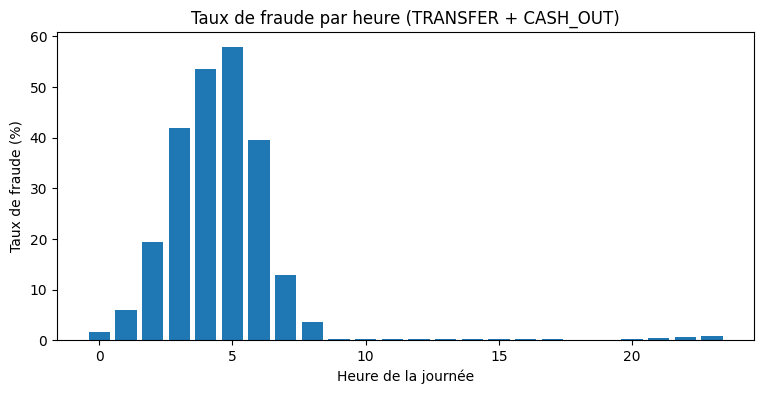

In [6]:
import matplotlib.pyplot as plt

par_heure = spark.sql("""
    SELECT HOUR(transaction_time) AS heure, 100 * AVG(label) AS taux_fraude_pct
    FROM transactions
    WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY HOUR(transaction_time)
    ORDER BY heure
""").toPandas()

plt.figure(figsize=(9, 4))
plt.bar(par_heure["heure"], par_heure["taux_fraude_pct"])
plt.xlabel("Heure de la journée")      # axe X
plt.ylabel("Taux de fraude (%)")       # axe Y
plt.title("Taux de fraude par heure (TRANSFER + CASH_OUT)")
plt.show()

Axe X : heure de la journée ; axe Y : taux de fraude.

Le taux de fraude est très élevé la nuit (jusqu'à environ 58 % vers 5 h) et presque nul en journée. Les fraudes sont réparties sur toute la journée, alors que les transactions normales se font surtout le jour. L'heure est donc une feature utile.

## Artefacts des soldes (mise en garde)

Dans le simulateur, un fraudeur vide presque toujours le compte, et les soldes du destinataire
restent souvent à 0. Ce tableau le mesure : il justifie la comparaison avec / sans soldes du notebook 03.

In [7]:
spark.sql("""
    SELECT label,
           ROUND(100 * AVG(CASE WHEN amount = oldbalanceOrg THEN 1 ELSE 0 END), 1) AS pct_montant_egal_solde,
           ROUND(100 * AVG(CASE WHEN newbalanceOrig = 0 THEN 1 ELSE 0 END), 1)     AS pct_compte_vide,
           ROUND(100 * AVG(CASE WHEN oldbalanceDest = 0 AND newbalanceDest = 0 THEN 1 ELSE 0 END), 1) AS pct_soldes_dest_nuls
    FROM transactions
    WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY label
""").show()

[Stage 21:================================>                         (5 + 4) / 9]

+-----+----------------------+---------------+--------------------+
|label|pct_montant_egal_solde|pct_compte_vide|pct_soldes_dest_nuls|
+-----+----------------------+---------------+--------------------+
|  0.0|                   0.0|           90.1|                 0.1|
|  1.0|                  92.5|           98.1|                47.0|
+-----+----------------------+---------------+--------------------+



92,5 % des fraudes ont un montant exactement égal au solde du compte, contre 0 % des transactions normales, et 47 % des fraudes ont des soldes destinataire à 0 avant et après. Ce sont des règles du simulateur : un modèle qui les utilise aura un très bon score, mais pas forcément réaliste. C'est pour ça qu'on compare avec et sans soldes dans le notebook 03.

## Préparation pour le Machine Learning

- on garde seulement `TRANSFER` et `CASH_OUT` (les seuls types avec des fraudes) ;
- séparation **80 % entraînement / 20 % test**. La validation se fait à l'intérieur de l'entraînement
  (notebook 03). Le test ne sert que dans le notebook 04.

In [8]:
ml = df.filter(F.col("type").isin("TRANSFER", "CASH_OUT"))

train, test = ml.randomSplit([0.8, 0.2], seed=42)

train.write.mode("overwrite").parquet(DATA + "/ml/train.parquet")
test.write.mode("overwrite").parquet(DATA + "/ml/test.parquet")

print("Entraînement :")
spark.read.parquet(DATA + "/ml/train.parquet").groupBy("label").count().show()
print("Test :")
spark.read.parquet(DATA + "/ml/test.parquet").groupBy("label").count().show()

Entraînement :
+-----+-------+
|label|  count|
+-----+-------+
|  0.0|2186139|
|  1.0|   6475|
+-----+-------+

Test :
+-----+------+
|label| count|
+-----+------+
|  0.0|546046|
|  1.0|  1642|
+-----+------+



Le taux de fraude est le même dans les deux jeux (environ 0,30 %) : la séparation aléatoire a gardé l'équilibre des classes.

In [9]:
spark.stop()